# 05. Early QAU Predictor — 가입 14일 차 행동으로 90일 안의 핵심 창작(D)을 예측

**요약**

- **테스트(학습 이후 기간 2025-07 ~ 09 가입자) PR-AUC 0.128** (95% CI 0.114 ~ 0.143), 정답 비율 2.46% 대비 **5.2배**. ROC-AUC 0.789. 같은 데이터의 로지스틱 회귀(0.098)보다 31% 높다.
- **상위 10%에 전환자의 43%가 모인다** (lift 4.3배). 규칙 그룹(노트북 작성자, 전환율 65%)을 맨 위에 두면 전체 대상 상위 2%의 정밀도 56%, 상위 10%가 전환자의 58%를 잡는다.
- **실험 기록 (시간 순 3-fold 평균)**: 로지스틱 0.133 → LightGBM 0.151 → 대회 맥락 보강 + 튜닝 0.160 → RFM 0.161. 가장 큰 개선은 중간 SHAP에서 출발한 **대회 맥락 보강**(끝난 대회 / 진행 중 대회 구분).
- **앙상블은 쓰지 않는다.** 평균은 0.162로 가장 높지만 fold 1에서 단일 모델보다 낮아 채택 규칙(모든 fold에서 향상)을 통과하지 못했다. XGBoost도 같은 이유로 보류.
- 성능은 **대회 맥락**(빼면 −0.023)에서 가장 많이 나온다. 데이터셋에 투표만 한 유저는 전환 가능성이 낮고, 막 열린 대회·마감까지 시간이 남은 대회에 참가한 유저는 높다.

| 섹션 | 내용 |
|---|---|
| §1 | 대상, 정답, 규칙 그룹과 모델 그룹, 시간 순 분할 |
| §2 | 피처 (활동량·시간·경로·대회 맥락·소셜, 대회 맥락 보강) + RFM |
| §3 | 실험 기록 (시간 순 3-fold): 기준선 → 튜닝 → 중간 SHAP → 피처 보강 → XGBoost → 앙상블 → RFM |
| §4 | 최종 모델 테스트 성능 (2025-07 ~ 09, 한 번) |
| §5 | 무엇이 성능을 만드나: 피처 묶음 ablation, 황금기 데이터 추가 (교차검증) |
| §6 | 최종 SHAP: 가설 후보 |

입력: `data/processed/ml_dataset.parquet` (`scripts/05_ml_dataset.py`)

In [1]:
import sys, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import xgboost as xgb
import optuna, shap
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve, brier_score_loss

sys.path.append("../src")
sys.path.append(os.path.expanduser("~/.claude/skills/chart-style"))
from metakaggle.config import processed, SEED
import viz_style as vs

vs.setup(); warnings.filterwarnings("ignore"); optuna.logging.set_verbosity(optuna.logging.WARNING)
FIG = "../docs/figures"
data = pd.read_parquet(processed("ml_dataset"))
data.groupby(["period", "segment"]).y.agg(["size", "mean"])

size      mean
period     segment                   
Golden     model     214850  0.042476
           notebook    2217  0.550293
Stagnation model     278456  0.027674
           notebook    4931  0.590144

## §1 대상, 정답, 분할

| 항목 | 정의 |
|---|---|
| 예측 시점 | 가입 후 14일 (D+14 당일까지의 기록만 사용, 날짜 단위) |
| 대상 | D+14까지 비-D 활동(가벼운 활동, 대회 참가, 노트북 작성)이 있고 D 활동은 없는 유저 |
| 정답 | D+15 ~ D+90에 D 활동(노트북 공개, 대회 제출, 포럼 글, 데이터셋·모델) 발생 |
| **규칙 그룹** | D+14까지 노트북을 작성한 유저 (대상의 약 2%). 이후 D 전환율이 55 ~ 59%라 모델 없이 "고가능성"으로 분류 |
| **모델 그룹** | 나머지 98%. 모델은 이 집단만 학습·평가 |
| 개발 기간 | 2024-07 ~ 2025-06 가입자 → **시간 순 교차검증**으로 실험·튜닝 |
| **테스트** | 2025-07 ~ 09 가입자. 마지막에 고른 모델 하나에만 한 번 사용 |
| 황금기 2020 | 학습에 넣었을 때 효과만 확인 (§5) |

**시간 순 교차검증 (rolling-origin, 확장 창)**: 학습 기간을 늘려가며 바로 다음 3개월로 검증한다.

| fold | 학습 | 검증 |
|---|---|---|
| 1 | 2024-07 ~ 09 | 2024-10 ~ 12 |
| 2 | 2024-07 ~ 12 | 2025-01 ~ 03 |
| 3 | 2024-07 ~ 2025-03 | 2025-04 ~ 06 |

- **층화 k-fold를 쓰지 않는 이유**: 무작위로 섞으면 미래 가입자로 학습해 과거 가입자를 맞히게 된다. 모델은 앞으로 들어올 가입자에게 쓰이므로 "과거로 학습, 미래로 평가"를 지킨다. 정답 비율은 기간별로 2.5 ~ 2.9%로 이미 비슷하다.
- **검증셋을 3개 쓰는 이유**: 검증 기간 하나의 정답은 약 1,500명이라 PR-AUC가 우연만으로 ±0.01 가까이 흔들린다. 3개 fold의 평균과 일관성으로 판단한다.

**왜 노트북 작성자를 따로 빼나**: 노트북 작성은 D+14에 알 수 있는 정당한 정보지만, 작성 → 공개(= D)가 정의상 가까워 이 그룹은 맞히기 쉽다. 섞어 두면 쉬운 2%가 성능 숫자를 부풀린다. 규칙으로 처리하고 모델은 **불확실한 98%**에서의 실력으로 평가한다.

In [2]:
stag = data[data.period == "Stagnation"]
model_df = stag[stag.segment == "model"].copy()
dev = model_df[model_df.cohort_month <= "2025-06"]
te = model_df[model_df.cohort_month >= "2025-07"]
FOLDS = [("2024-09", "2024-12"), ("2024-12", "2025-03"), ("2025-03", "2025-06")]     # (학습 끝 월, 검증 끝 월)
folds = [(dev[dev.cohort_month <= a], dev[(dev.cohort_month > a) & (dev.cohort_month <= b)]) for a, b in FOLDS]
golden = data[(data.period == "Golden") & (data.segment == "model")]
rule = stag[stag.segment == "notebook"]
rows = [(f"fold {i+1} 학습", f_tr) for i, (f_tr, _) in enumerate(folds)] + [(f"fold {i+1} 검증", f_va) for i, (_, f_va) in enumerate(folds)]
rows += [("개발 전체 (2024-07 ~ 2025-06)", dev), ("테스트 (2025-07 ~ 09)", te), ("규칙 그룹 (침체기 노트북 작성자)", rule), ("황금기 2020 (비교용)", golden)]
pd.DataFrame({"인원": [len(d) for _, d in rows], "정답 비율": [d.y.mean() for _, d in rows]}, index=[n for n, _ in rows]).style.format({"인원": "{:,}", "정답 비율": "{:.2%}"})

,인원,정답 비율
fold 1 학습,"52,117",2.71%
fold 2 학습,"111,891",2.81%
fold 3 학습,"165,713",2.87%
fold 1 검증,"59,774",2.91%
fold 2 검증,"53,822",3.00%
fold 3 검증,"56,343",2.76%
개발 전체 (2024-07 ~ 2025-06),"222,056",2.84%
테스트 (2025-07 ~ 09),"56,400",2.46%
규칙 그룹 (침체기 노트북 작성자),"4,931",59.01%
황금기 2020 (비교용),"214,850",4.25%


## §2 피처

모든 피처는 D+0 ~ D+14 당일까지. 팀 크기는 D+14까지 합류한 팀원만 센다. `Users.Country`·`PerformanceTier`는 현재 시점 값이라 쓰지 않는다.

| 묶음 | 피처 |
|---|---|
| 활동량 | 가벼운 활동 종류별 건수(팔로우, 투표 3종, 반응), 팀 합류 수, 가벼운 활동 합계·종류 수 |
| 시간 | 활동일 수, 첫·마지막 활동일, 최근성, 가입 당일 활동, D+1~7·D+8~14 활동일 수, 가입 요일 |
| 경로 | 첫 활동이 대회 참가인지, 가벼운 활동만 했는지 (`04` 프로세스 마이닝의 핵심 분기) |
| 대회 맥락 | D+14 시점 팀 크기, 첫 팀 합류일, 마감까지 남은 일수, 상금, 첫 대회 종류(Featured·Research·Playground·Community·입문) |
| 소셜 | 받은 팔로우 수 |
| **대회 맥락 보강** (2차) | 끝난 / 진행 중 대회 참가 수와 비율, 참가 시점의 대회 인기(그날까지 생긴 팀 수), 대회가 열린 지 며칠, 노트북 제출 전용 대회, Playground Series, 남의 팀 합류, 상금 종류 |

**보강한 이유**: 1차 모델의 SHAP 1위가 "마감까지 남은 일수"였다. 신규 유저가 가장 많이 참가한 대회는 2013년에 끝난 dogs-vs-cats 같은 대회였다. 끝난 대회 "참가"는 데이터를 받으려고 규칙에 동의한 것일 가능성이 크다 → 진행 중 대회 참가와 구분하는 피처를 만들었다. 대회의 최종 팀 수(`TotalTeams`)는 미래 정보라 쓰지 않고, 참가한 날까지 생긴 팀 수만 센다. `TeamLeaderId`는 현재 값이라 바뀌었을 수 있다(대부분 1인 팀이라 영향은 작음).

### RFM (넣은 버전 / 뺀 버전 비교)
- **R** = D+14 기준 마지막 활동 후 경과일(작을수록 좋음), **F** = 활동일 수, **M** = 본인 활동 총 건수 (금액이 없어 활동량으로 대체)
- 각각 1 ~ 5점. 구간 경계는 **각 fold의 학습셋에서만** 정해 그 fold의 검증셋에 그대로 적용
- R·F 조합으로 세그먼트: 활발 지속(R≥4, F≥4) / 최근 시작(R≥4) / 식어감(F≥3) / 한 번 방문(R≤2, F≤2) / 그 외

In [3]:
GROUPS = {
    "활동량": ["n_follow", "n_vote_model", "n_vote_dataset", "n_vote_forum", "n_reaction", "n_team", "n_teams", "n_light", "n_light_types"],
    "시간": ["active_days", "first_day", "last_day", "recency", "active_d0", "active_d1_7", "active_d8_14", "reg_weekday"],
    "경로": ["first_is_team", "light_only"],
    "대회 맥락": ["max_team_size_d14", "first_team_day", "min_days_to_deadline", "max_reward", "comp_featured", "comp_research",
              "comp_playground", "comp_community", "comp_getting_started"],
    "소셜": ["n_followed_by"],
}
V1 = sum(GROUPS.values(), [])
COMP_V2 = ["n_closed_comps", "n_open_comps", "share_closed_comps", "max_comp_teams_at_join_open", "min_comp_age",
           "any_kernels_only", "any_playground_series", "any_joined_others_team", "first_reward_usd", "first_reward_knowledge"]
GROUPS["대회 맥락 보강"] = COMP_V2
BASE = V1 + COMP_V2

class RFM:
    """R·F·M 1~5점과 세그먼트. 구간 경계는 fit(학습셋)에서만 정한다."""
    def fit(self, df):
        self.edges = {k: np.unique(np.quantile(v, [0.2, 0.4, 0.6, 0.8])) for k, v in self._raw(df).items()}
        return self
    def _raw(self, df):
        return {"R": -df.recency.fillna(15), "F": df.active_days, "M": df.n_light + df.n_team}   # R은 클수록 좋게 부호 반전
    def transform(self, df):
        out = pd.DataFrame(index=df.index)
        for k, v in self._raw(df).items():
            out[f"rfm_{k}"] = np.digitize(v, self.edges[k], right=True) + 1
        out["rfm_sum"] = out[["rfm_R", "rfm_F", "rfm_M"]].sum(axis=1)
        r, f = out.rfm_R, out.rfm_F
        seg = np.select([(r >= 4) & (f >= 4), r >= 4, f >= 3, (r <= 2) & (f <= 2)], ["활발 지속", "최근 시작", "식어감", "한 번 방문"], "그 외")
        for s in ["활발 지속", "최근 시작", "식어감", "한 번 방문"]:
            out[f"rfm_seg_{s}"] = (seg == s).astype("int8")
        out["rfm_segment"] = seg
        return out

RFM_COLS = ["rfm_R", "rfm_F", "rfm_M", "rfm_sum", "rfm_seg_활발 지속", "rfm_seg_최근 시작", "rfm_seg_식어감", "rfm_seg_한 번 방문"]
def with_rfm(train, *others):
    """train에서 구간 경계를 정하고 모든 데이터에 RFM 열을 붙인다 (fold마다 따로)"""
    r = RFM().fit(train)
    return [pd.concat([d, r.transform(d)], axis=1) for d in (train, *others)]

rfm_dev = RFM().fit(dev)
print("구간 경계 (개발 기간):", {k: v.tolist() for k, v in rfm_dev.edges.items()})
print("활동일 수 분포:", dev.active_days.value_counts(normalize=True).sort_index().head(4).round(3).to_dict())
seg_tbl = dev.join(rfm_dev.transform(dev)).groupby("rfm_segment").y.agg(["size", "mean"]).rename(columns={"size": "인원", "mean": "D 전환율"}).sort_values("D 전환율", ascending=False)
seg_tbl.style.format({"인원": "{:,}", "D 전환율": "{:.2%}"}).set_caption("RFM 세그먼트별 D 전환율 (개발 기간)")

구간 경계 (개발 기간): {'R': [-14.0, -11.0], 'F': [1.0], 'M': [1.0]}
활동일 수 분포: {1: 0.953, 2: 0.042, 3: 0.004, 4: 0.001}


,인원,D 전환율
rfm_segment,,
그 외,"44,266",6.18%
한 번 방문,"177,790",2.01%


## §3 실험 기록 (시간 순 교차검증, 테스트는 보지 않음)

한 번에 하나씩 바꾸고 3개 fold의 검증 PR-AUC로 채택 여부를 정한다.

**채택 규칙** (결과 보기 전에 고정): 지금까지 채택된 최고 모델보다 **3개 fold 평균이 오르고, 3개 fold 모두에서 오를 때** 채택한다. 하나라도 떨어지면 우연한 향상일 수 있으므로 더 단순한 쪽을 유지한다.

| 단계 | 바꾸는 것 |
|---|---|
| E1 ~ E3 | 기준선: 랜덤, 규칙(대회 참가 여부), 로지스틱 회귀 |
| E4 | LightGBM 기본값, 1차 피처 |
| E5 | + Optuna 튜닝 (20회, 목표 = 3개 fold 평균 PR-AUC) |
| → | **중간 SHAP**: 무엇을 더 만들지 정한다 |
| E6 | + 대회 맥락 보강 피처 |
| E7 | + 다시 튜닝 |
| E8 | XGBoost (같은 피처, 튜닝) |
| E9 | 앙상블 (E7 + E8 평균) |
| E10 | + RFM |

In [4]:
def prep_linear(df, cols):
    X = df[cols].astype(float).copy()
    for c in cols:
        if X[c].isna().any():
            X[f"{c}_na"] = X[c].isna().astype(float); X[c] = X[c].fillna(-1)
        if c.startswith("n_") or c in ("max_reward", "max_comp_teams_at_join_open"):
            X[c] = np.log1p(X[c].clip(lower=0))
    return X

def fit_model(kind, params, tr, va, cols):
    if kind == "lgb":
        m = lgb.LGBMClassifier(n_estimators=3000, random_state=SEED, verbose=-1, **params)
        m.fit(tr[cols], tr.y, eval_set=[(va[cols], va.y)], eval_metric="average_precision", callbacks=[lgb.early_stopping(100, verbose=False)])
    else:
        m = xgb.XGBClassifier(n_estimators=3000, tree_method="hist", eval_metric="aucpr", early_stopping_rounds=100, random_state=SEED, n_jobs=-1, **params)
        m.fit(tr[cols], tr.y, eval_set=[(va[cols], va.y)], verbose=False)
    return m

def best_iter(m):
    return m.best_iteration_ if hasattr(m, "best_iteration_") else m.best_iteration + 1

def cv(kind, params, cols, rfm=False, extra_train=None):
    """3개 fold 검증 PR-AUC 목록, 모델 목록"""
    scores, ms = [], []
    for f_tr, f_va in folds:
        if extra_train is not None:
            f_tr = pd.concat([f_tr, extra_train])
        if rfm:
            f_tr, f_va = with_rfm(f_tr, f_va)
        m = fit_model(kind, params, f_tr, f_va, cols)
        scores.append(average_precision_score(f_va.y, m.predict_proba(f_va[cols])[:, 1])); ms.append(m)
    return np.array(scores), ms

def space(kind, t):
    common = dict(learning_rate=t.suggest_float("learning_rate", 0.01, 0.15, log=True), subsample=t.suggest_float("subsample", 0.6, 1.0),
                  colsample_bytree=t.suggest_float("colsample_bytree", 0.5, 1.0), reg_lambda=t.suggest_float("reg_lambda", 1e-3, 30, log=True))
    if kind == "lgb":
        return dict(common, num_leaves=t.suggest_int("num_leaves", 8, 128, log=True), min_child_samples=t.suggest_int("min_child_samples", 20, 800, log=True), subsample_freq=1)
    return dict(common, max_depth=t.suggest_int("max_depth", 2, 8), min_child_weight=t.suggest_float("min_child_weight", 1, 100, log=True))

def tune(kind, cols, rfm=False, n_trials=20):
    st = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    st.optimize(lambda t: cv(kind, space(kind, t), cols, rfm)[0].mean(), n_trials=n_trials)
    params = space(kind, optuna.trial.FixedTrial(st.best_params))
    return params

DEFAULT_LGB = dict(learning_rate=0.05, num_leaves=31)
log, runs = [], {}
def record(step, desc, scores, kind=None, params=None, cols=None, rfm=False, ms=None):
    log.append({"단계": step, "내용": desc, "평균": scores.mean(), "fold 1": scores[0], "fold 2": scores[1], "fold 3": scores[2], "표준편차": scores.std()})
    runs[step] = dict(kind=kind, params=params, cols=cols, rfm=rfm, scores=scores, models=ms)

record("E1", "랜덤", np.array([f_va.y.mean() for _, f_va in folds]))
record("E2", "규칙: 대회 참가 여부", np.array([average_precision_score(f_va.y, (f_va.n_team > 0).astype(float)) for _, f_va in folds]))
lr_scores = []
for f_tr, f_va in folds:
    lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.5)).fit(prep_linear(f_tr, BASE), f_tr.y)
    lr_scores.append(average_precision_score(f_va.y, lr.predict_proba(prep_linear(f_va, BASE))[:, 1]))
record("E3", "로지스틱 회귀 (전체 피처)", np.array(lr_scores))
for step, desc, kind, cols, rfm, tuned in [("E4", "LightGBM 기본값, 1차 피처", "lgb", V1, False, False),
                                           ("E5", "+ 튜닝", "lgb", V1, False, True)]:
    params = tune(kind, cols, rfm) if tuned else DEFAULT_LGB
    sc, ms = cv(kind, params, cols, rfm); record(step, desc, sc, kind, params, cols, rfm, ms)
pd.DataFrame(log).set_index("단계").style.format({c: "{:.4f}" for c in ["평균", "fold 1", "fold 2", "fold 3", "표준편차"]})

,내용,평균,fold 1,fold 2,fold 3,표준편차
단계,,,,,,
E1,랜덤,0.0289,0.0291,0.0300,0.0276,0.0010
E2,규칙: 대회 참가 여부,0.0432,0.0426,0.0439,0.0432,0.0006
E3,로지스틱 회귀 (전체 피처),0.1327,0.1300,0.1518,0.1164,0.0146
E4,"LightGBM 기본값, 1차 피처",0.1512,0.1730,0.1652,0.1155,0.0255
E5,+ 튜닝,0.1527,0.1663,0.1695,0.1223,0.0215


### 중간 SHAP: 다음에 무엇을 만들까 (E5, fold 3 검증 기간)

1차 모델이 무엇에 기대는지 보고 피처 보강 방향을 정한다. 이상하게 강한 피처가 있으면 누수도 의심한다.

[]


,mean |SHAP|,이름,방향
n_vote_dataset,0.205847,데이터셋 투표 수,-
min_days_to_deadline,0.183900,참가 대회 마감까지 남은 일수,+
last_day,0.175275,마지막 활동일,+
max_reward,0.050579,참가 대회 상금,+
n_follow,0.049121,팔로우 수,+
recency,0.029837,마지막 활동 후 경과일,-
n_team,0.023233,팀 합류 수,+
max_team_size_d14,0.019946,D+14 팀 크기,-
first_team_day,0.019480,첫 대회 참가일,+
active_d8_14,0.016985,D+8~14 활동일 수,+


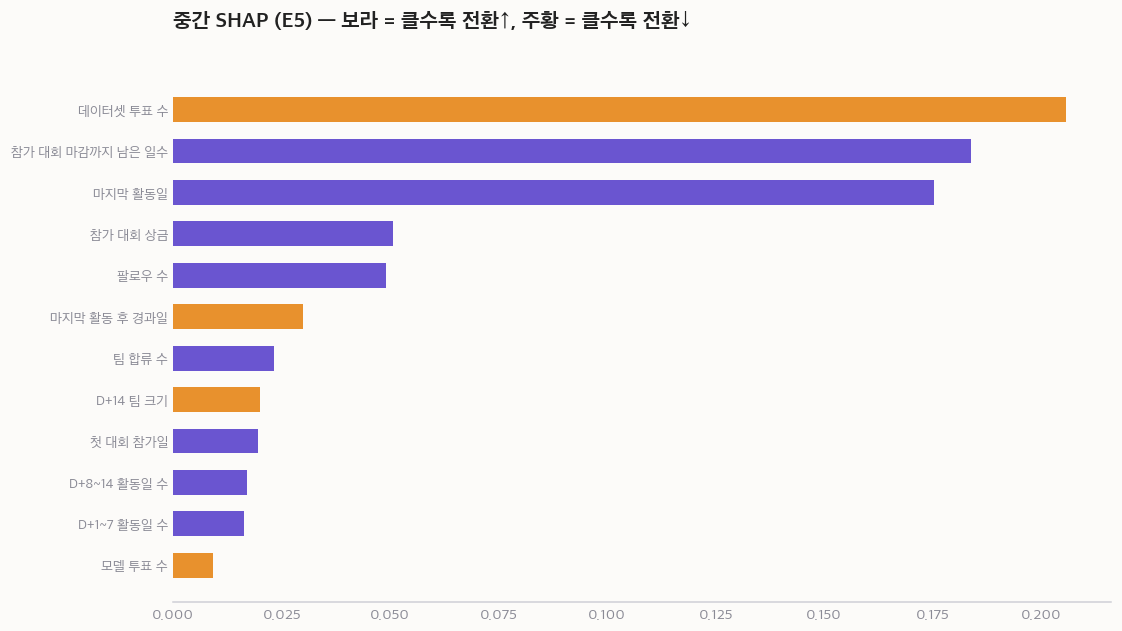

In [5]:
LABEL = {"min_days_to_deadline": "참가 대회 마감까지 남은 일수", "n_vote_dataset": "데이터셋 투표 수", "last_day": "마지막 활동일",
         "n_follow": "팔로우 수", "max_reward": "참가 대회 상금", "max_team_size_d14": "D+14 팀 크기", "recency": "마지막 활동 후 경과일",
         "first_team_day": "첫 대회 참가일", "n_team": "팀 합류 수", "first_is_team": "첫 활동이 대회 참가", "active_d8_14": "D+8~14 활동일 수",
         "active_days": "활동일 수", "active_d1_7": "D+1~7 활동일 수", "n_vote_model": "모델 투표 수", "first_day": "첫 활동일",
         "n_vote_forum": "포럼 투표 수", "n_light": "가벼운 활동 수", "light_only": "가벼운 활동만", "n_followed_by": "받은 팔로우 수",
         "comp_featured": "첫 대회 Featured", "comp_playground": "첫 대회 Playground", "comp_research": "첫 대회 Research",
         "comp_community": "첫 대회 Community", "comp_getting_started": "첫 대회 입문용", "n_teams": "참가 팀 수", "active_d0": "가입 당일 활동",
         "n_light_types": "가벼운 활동 종류 수", "n_reaction": "반응 수", "reg_weekday": "가입 요일",
         "n_closed_comps": "끝난 대회 참가 수", "n_open_comps": "진행 중 대회 참가 수", "share_closed_comps": "끝난 대회 참가 비율",
         "max_comp_teams_at_join_open": "참가 시점 대회 인기", "min_comp_age": "대회가 열린 지 일수", "any_kernels_only": "노트북 제출 전용 대회",
         "any_playground_series": "Playground Series 참가", "any_joined_others_team": "남의 팀 합류", "first_reward_usd": "첫 대회 상금(USD)",
         "first_reward_knowledge": "첫 대회 상금 없음(Knowledge)", "rfm_R": "RFM R 점수", "rfm_F": "RFM F 점수", "rfm_M": "RFM M 점수",
         "rfm_sum": "RFM 합계 점수", "rfm_seg_한 번 방문": "RFM 한 번 방문"}

def shap_bar(model, X, title, path, top=12):
    sv = shap.TreeExplainer(model).shap_values(X)
    sv = sv[1] if isinstance(sv, list) else sv
    imp = pd.Series(np.abs(sv).mean(0), index=X.columns).sort_values(ascending=False).head(top)
    # 방향: 값이 있는 행만으로 피처 값과 SHAP의 순위 상관 (결측 = 해당 없음은 제외)
    def _dir(i, c):
        ok = X[c].notna().values
        return pd.Series(X[c].values[ok]).corr(pd.Series(sv[ok, i]), method="spearman") if X[c][ok].nunique() > 1 else 0
    direction = pd.Series([_dir(i, c) for i, c in enumerate(X.columns)], index=X.columns).fillna(0)
    fig, ax = plt.subplots(figsize=(11, 0.42 * top + 1.2))
    y = np.arange(len(imp))[::-1]
    ax.barh(y, imp.values, color=[vs.PURPLE if direction[c] > 0 else vs.ORANGE for c in imp.index], height=0.6)
    ax.set_yticks(y); ax.set_yticklabels([LABEL.get(c, c) for c in imp.index], fontsize=9); ax.grid(axis="y", visible=False)
    ax.set_title(title, loc="left", fontweight="bold")
    fig.savefig(path, dpi=120, bbox_inches="tight"); print(vs.check_overlaps(fig))
    return imp.to_frame("mean |SHAP|").assign(이름=[LABEL.get(c, c) for c in imp.index], 방향=["+" if direction[c] > 0 else "-" for c in imp.index]), sv

f3_va = folds[2][1]
mid_imp, _ = shap_bar(runs["E5"]["models"][2], f3_va[V1].sample(min(20000, len(f3_va)), random_state=SEED),
                      "중간 SHAP (E5) — 보라 = 클수록 전환↑, 주황 = 클수록 전환↓", f"{FIG}/05_shap_mid.png")
mid_imp

**→ 보강 방향**: 1위가 "참가 대회 마감까지 남은 일수"다. 신규 유저가 가장 많이 참가한 대회를 보면 2013년에 끝난 dogs-vs-cats, ImageNet처럼 **이미 끝난 대회**가 상위다. 끝난 대회 "참가"는 데이터를 받으려고 규칙에 동의한 것일 가능성이 크다. 그래서 끝난 대회 / 진행 중 대회 참가를 구분하고, 참가 시점의 대회 성격(인기, 나이, 노트북 제출 전용, 상금 종류, 남의 팀 합류)을 더한다 (§2 "대회 맥락 보강").

In [6]:
for step, desc, kind, cols, rfm, tuned in [("E6", "+ 대회 맥락 보강 (기본값)", "lgb", BASE, False, False),
                                           ("E7", "+ 다시 튜닝", "lgb", BASE, False, True),
                                           ("E8", "XGBoost (튜닝)", "xgb", BASE, False, True)]:
    params = tune(kind, cols, rfm) if tuned else DEFAULT_LGB
    sc, ms = cv(kind, params, cols, rfm); record(step, desc, sc, kind, params, cols, rfm, ms)
ens = np.array([average_precision_score(f_va.y, (runs["E7"]["models"][i].predict_proba(f_va[BASE])[:, 1] +
                                                 runs["E8"]["models"][i].predict_proba(f_va[BASE])[:, 1]) / 2) for i, (_, f_va) in enumerate(folds)])
record("E9", "앙상블 (E7 + E8 평균)", ens, "ens", None, BASE)
params = tune("lgb", BASE + RFM_COLS, rfm=True)
sc, ms = cv("lgb", params, BASE + RFM_COLS, rfm=True); record("E10", "+ RFM (LightGBM 튜닝)", sc, "lgb", params, BASE + RFM_COLS, True, ms)

best = None
for row in log:
    if row["단계"] in ("E1", "E2", "E3"):
        row["채택"] = "기준선"; continue
    sc = runs[row["단계"]]["scores"]
    if best is None or (sc.mean() > runs[best]["scores"].mean() and (sc > runs[best]["scores"]).all()):
        row["채택"] = "채택"; best = row["단계"]
    else:
        row["채택"] = "보류"
exp = pd.DataFrame(log).set_index("단계")
exp["랜덤 대비"] = exp["평균"] / exp.loc["E1", "평균"]
CHOSEN = best
print("최종 모델:", CHOSEN, exp.loc[CHOSEN, "내용"])
exp.style.format({c: "{:.4f}" for c in ["평균", "fold 1", "fold 2", "fold 3", "표준편차"]} | {"랜덤 대비": "{:.1f}배"})

최종 모델: E10 + RFM (LightGBM 튜닝)


,내용,평균,fold 1,fold 2,fold 3,표준편차,채택,랜덤 대비
단계,,,,,,,,
E1,랜덤,0.0289,0.0291,0.0300,0.0276,0.0010,기준선,1.0배
E2,규칙: 대회 참가 여부,0.0432,0.0426,0.0439,0.0432,0.0006,기준선,1.5배
E3,로지스틱 회귀 (전체 피처),0.1327,0.1300,0.1518,0.1164,0.0146,기준선,4.6배
E4,"LightGBM 기본값, 1차 피처",0.1512,0.1730,0.1652,0.1155,0.0255,채택,5.2배
E5,+ 튜닝,0.1527,0.1663,0.1695,0.1223,0.0215,보류,5.3배
E6,+ 대회 맥락 보강 (기본값),0.1479,0.1531,0.1632,0.1274,0.0151,보류,5.1배
E7,+ 다시 튜닝,0.1603,0.1763,0.1712,0.1335,0.0191,채택,5.6배
E8,XGBoost (튜닝),0.1618,0.1736,0.1746,0.1371,0.0175,보류,5.6배
E9,앙상블 (E7 + E8 평균),0.1622,0.1759,0.1746,0.1362,0.0184,보류,5.6배


[]


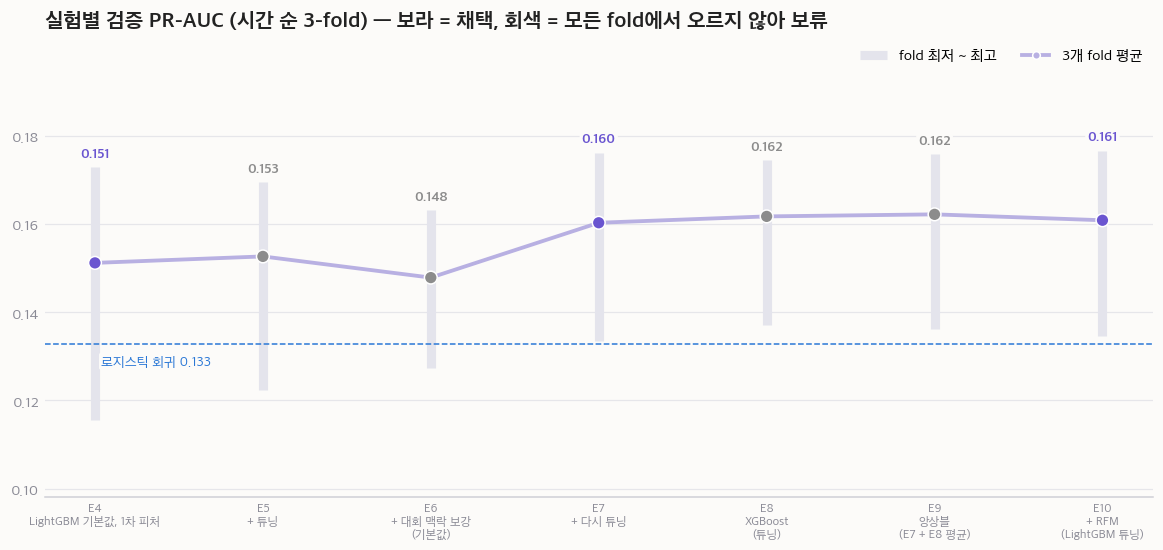

In [7]:
fig, ax = plt.subplots(figsize=(13, 5))
steps = exp.index[3:]; x = np.arange(len(steps)); v = exp.loc[steps, "평균"].values
lo = exp.loc[steps, ["fold 1", "fold 2", "fold 3"]].min(axis=1).values; hi = exp.loc[steps, ["fold 1", "fold 2", "fold 3"]].max(axis=1).values
ax.vlines(x, lo, hi, color=vs.SHADE_GRAY, lw=6, zorder=1, label="fold 최저 ~ 최고")
vs.line(ax, x, v, vs.LAVENDER, "3개 fold 평균")
adopted = [exp.loc[s, "채택"] == "채택" for s in steps]
ax.scatter(x, v, c=[vs.PURPLE if a else vs.GRAY for a in adopted], s=70, zorder=4, edgecolor="white")
for xi, vi, h, a in zip(x, v, hi, adopted):
    ax.annotate(f"{vi:.3f}", (xi, h), xytext=(0, 6), textcoords="offset points", ha="center", fontsize=9,
                color=vs.PURPLE if a else vs.GRAY, fontweight="bold", bbox=vs.LABEL_BOX)
ax.axhline(exp.loc["E3", "평균"], color=vs.BLUE, ls="--", lw=1)
ax.annotate(f"로지스틱 회귀 {exp.loc['E3', '평균']:.3f}", (x[0], exp.loc["E3", "평균"]), xytext=(4, -14), textcoords="offset points", ha="left", color=vs.BLUE, fontsize=9, bbox=vs.LABEL_BOX)
ax.set_xticks(x); ax.set_xticklabels([f"{s}\n{exp.loc[s, '내용'].replace(' (', chr(10) + '(')}" for s in steps], fontsize=8)
ax.set_ylim(min(lo.min(), exp.loc["E3", "평균"]) * 0.85, hi.max() * 1.1); ax.yaxis.set_major_locator(plt.MaxNLocator(5))
ax.set_title("실험별 검증 PR-AUC (시간 순 3-fold) — 보라 = 채택, 회색 = 모든 fold에서 오르지 않아 보류", loc="left", fontweight="bold")
vs.legend_top_right(ax)
fig.savefig(f"{FIG}/05_experiments.png", dpi=120, bbox_inches="tight"); print(vs.check_overlaps(fig))

## §4 최종 모델 테스트 성능 (2025-07 ~ 09 가입자, 한 번만)

채택된 설정으로 **개발 기간 전체(2024-07 ~ 2025-06)**에 다시 학습한다. 조기 종료에 쓸 검증셋이 없으므로 나무 개수는 3개 fold 최적값의 평균으로 고정한다.

In [8]:
R = runs[CHOSEN]
class Ens:
    def __init__(self, a, b): self.a, self.b = a, b
    def predict_proba(self, X): return (self.a.predict_proba(X) + self.b.predict_proba(X)) / 2

def refit_full(run, train):
    n = int(np.mean([best_iter(m) for m in run["models"]]))
    if run["kind"] == "lgb":
        return lgb.LGBMClassifier(n_estimators=n, random_state=SEED, verbose=-1, **run["params"]).fit(train[run["cols"]], train.y)
    return xgb.XGBClassifier(n_estimators=n, tree_method="hist", random_state=SEED, n_jobs=-1, **run["params"]).fit(train[run["cols"]], train.y)

dev_f, te_f = with_rfm(dev, te) if R["rfm"] else (dev, te)
if R["kind"] == "ens":
    final = Ens(refit_full(runs["E7"], dev_f), refit_full(runs["E8"], dev_f)); EXPLAIN, EXPLAIN_RUN = final.a, runs["E7"]
else:
    final = refit_full(R, dev_f); EXPLAIN, EXPLAIN_RUN = final, R
FCOLS = R["cols"]

rng = np.random.default_rng(SEED)
p_te = final.predict_proba(te_f[FCOLS])[:, 1]; y_te = te_f.y.values
def at_top(y, p, frac):
    k = int(len(p) * frac); idx = np.argsort(-p)[:k]
    return y[idx].mean(), y[idx].sum() / y.sum()
boot = [average_precision_score(y_te[i], p_te[i]) for i in (rng.integers(0, len(y_te), len(y_te)) for _ in range(500))]
prec10, rec10 = at_top(y_te, p_te, 0.10)
lr_full = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.5)).fit(prep_linear(dev, BASE), dev.y)
p_lr = lr_full.predict_proba(prep_linear(te, BASE))[:, 1]
perf = pd.Series({"모델": f"{CHOSEN} {exp.loc[CHOSEN, '내용']}", "정답 비율": y_te.mean(), "PR-AUC": average_precision_score(y_te, p_te),
                  "PR-AUC 95% CI": f"[{np.percentile(boot, 2.5):.4f}, {np.percentile(boot, 97.5):.4f}]",
                  "랜덤 대비": average_precision_score(y_te, p_te) / y_te.mean(), "ROC-AUC": roc_auc_score(y_te, p_te),
                  "상위 10% 정밀도": prec10, "상위 10% 재현율": rec10, "상위 10% lift": prec10 / y_te.mean(),
                  "Brier": brier_score_loss(y_te, p_te), "로지스틱 회귀 PR-AUC (참고)": average_precision_score(y_te, p_lr)}, name="테스트")
perf.to_frame()

,테스트
모델,E10 + RFM (LightGBM 튜닝)
정답 비율,0.024628
PR-AUC,0.12778
PR-AUC 95% CI,"[0.1140, 0.1434]"
랜덤 대비,5.188474
ROC-AUC,0.789285
상위 10% 정밀도,0.106915
상위 10% 재현율,0.434125
상위 10% lift,4.341253
Brier,0.022813


In [9]:
# 규칙 + 모델을 합친 운영 성능: 노트북 작성자(규칙)를 맨 위, 나머지는 모델 점수 순
rule_te = rule[rule.cohort_month >= "2025-07"]
y_all = np.r_[rule_te.y.values, y_te]; s_all = np.r_[np.full(len(rule_te), 2.0), p_te]
rows = []
for frac in [0.02, 0.05, 0.10, 0.20]:
    pr, rc = at_top(y_all, s_all, frac)
    rows.append({"상위": f"{frac:.0%}", "정밀도": pr, "재현율": rc, "lift": pr / y_all.mean()})
print(f"테스트 기간 전체 대상 {len(y_all):,}명 (규칙 그룹 {len(rule_te):,}명, 전환율 {rule_te.y.mean():.1%}), 정답 비율 {y_all.mean():.2%}")
pd.DataFrame(rows).set_index("상위").style.format({"정밀도": "{:.1%}", "재현율": "{:.1%}", "lift": "{:.1f}배"})

테스트 기간 전체 대상 57,237명 (규칙 그룹 837명, 전환율 65.4%), 정답 비율 3.38%


,정밀도,재현율,lift
상위,,,
2%,55.5%,32.8%,16.4배
5%,30.6%,45.2%,9.0배
10%,19.5%,57.7%,5.8배
20%,12.2%,71.9%,3.6배


["텍스트 겹침: '1.2' ↔ '1'"]


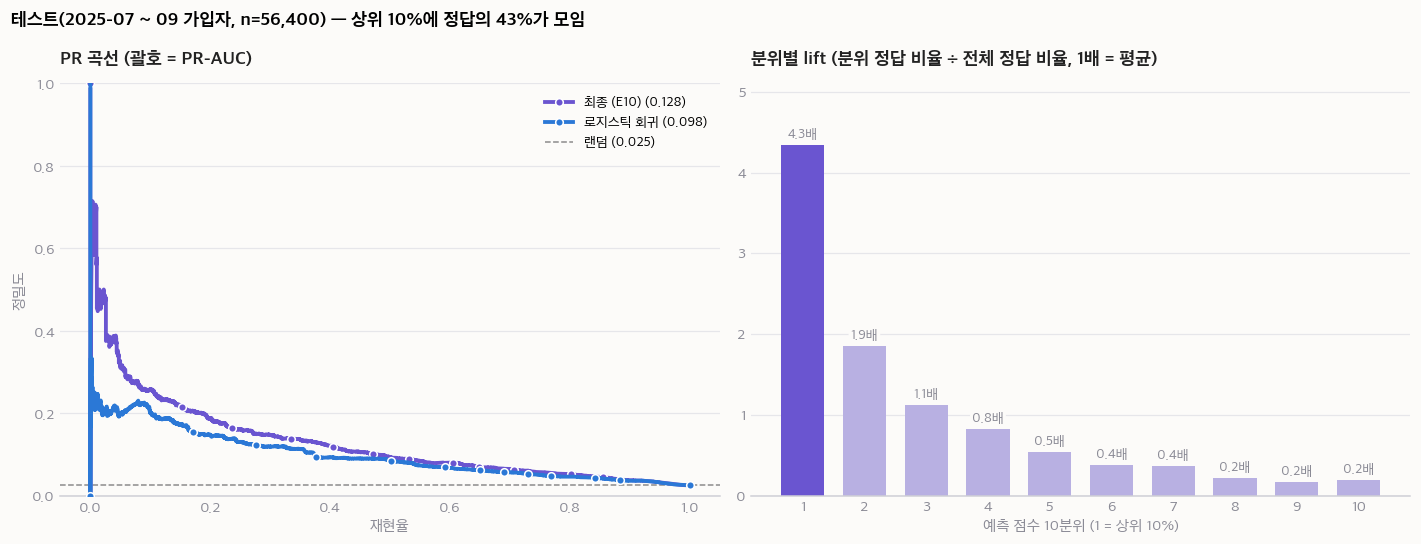

In [10]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5))
for name, p, c in [(f"최종 ({CHOSEN})", p_te, vs.PURPLE), ("로지스틱 회귀", p_lr, vs.BLUE)]:
    pr, rc, _ = precision_recall_curve(y_te, p)
    vs.line(a1, rc, pr, c, f"{name} ({average_precision_score(y_te, p):.3f})", markevery=max(1, len(rc) // 12))
a1.axhline(y_te.mean(), color=vs.GRAY, ls="--", lw=1, label=f"랜덤 ({y_te.mean():.3f})")
a1.set_xlabel("재현율"); a1.set_ylabel("정밀도"); a1.set_ylim(0, 1)
vs.panel_title(a1, "PR 곡선 (괄호 = PR-AUC)"); a1.legend(frameon=False, fontsize=9, loc="upper right")
dec = pd.qcut(pd.Series(p_te).rank(method="first"), 10, labels=False)
lift = pd.Series(y_te).groupby(9 - dec.values).mean() / y_te.mean()
bars = a2.bar(np.arange(1, 11), lift.values, color=[vs.PURPLE] + [vs.LAVENDER] * 9, width=0.7)
vs.label_bars(a2, bars, fmt=lambda v: f"{v:.1f}배")
a2.set_xticks(np.arange(1, 11)); a2.set_xlabel("예측 점수 10분위 (1 = 상위 10%)")
vs.panel_title(a2, "분위별 lift (분위 정답 비율 ÷ 전체 정답 비율, 1배 = 평균)")
fig.suptitle(f"테스트(2025-07 ~ 09 가입자, n={len(y_te):,}) — 상위 10%에 정답의 {rec10:.0%}가 모임", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(f"{FIG}/05_test_performance.png", dpi=120, bbox_inches="tight")
print(vs.check_overlaps(fig))

## §5 무엇이 성능을 만드나 (시간 순 교차검증)

### 5.1 피처 묶음 ablation
최종 설정에서 묶음 하나씩 빼고 3개 fold 평균 PR-AUC가 얼마나 떨어지는지 본다. 테스트는 쓰지 않는다.

[]


,빼면 PR-AUC 변화
대회 맥락,-0.023186
대회 맥락 보강,-0.008527
소셜,-0.006240
활동량,-0.004658
시간,-0.002820
RFM,-0.000567
경로,0.000484


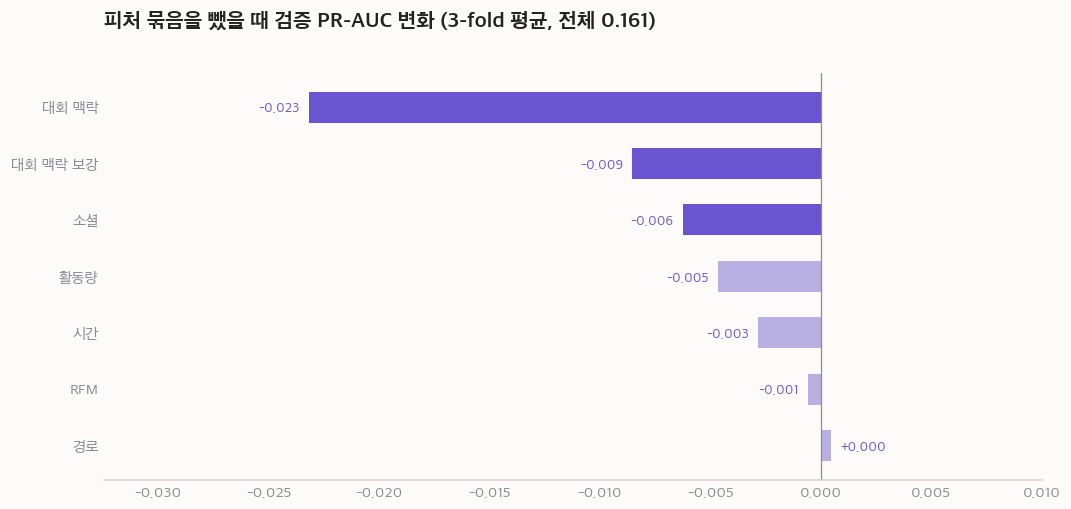

In [11]:
ER = EXPLAIN_RUN
full_cv = cv(ER["kind"], ER["params"], ER["cols"], ER["rfm"])[0].mean()
groups = dict(GROUPS, **({"RFM": RFM_COLS} if ER["rfm"] else {}))
abl = pd.Series({g: cv(ER["kind"], ER["params"], [c for c in ER["cols"] if c not in cols], ER["rfm"])[0].mean() - full_cv
                 for g, cols in groups.items()}).sort_values()
fig, ax = plt.subplots(figsize=(11, 4.8))
y = np.arange(len(abl))[::-1]
ax.barh(y, abl.values, color=[vs.PURPLE if v < -0.005 else vs.LAVENDER for v in abl.values], height=0.55)
for yi, v in zip(y, abl.values):
    ax.annotate(f"{v:+.3f}", (v, yi), xytext=(-6 if v < 0 else 6, 0), textcoords="offset points", ha="right" if v < 0 else "left",
                va="center", fontsize=9, color=vs.PURPLE, bbox=vs.LABEL_BOX)
ax.set_yticks(y); ax.set_yticklabels(abl.index); ax.axvline(0, color=vs.GRAY, lw=0.8); ax.grid(axis="y", visible=False)
ax.set_xlim(min(abl.min() * 1.4, -0.01), 0.01)
ax.set_title(f"피처 묶음을 뺐을 때 검증 PR-AUC 변화 (3-fold 평균, 전체 {full_cv:.3f})", loc="left", fontweight="bold")
fig.savefig(f"{FIG}/05_ablation.png", dpi=120, bbox_inches="tight"); print(vs.check_overlaps(fig))
abl.to_frame("빼면 PR-AUC 변화")

### 5.2 황금기 데이터를 학습에 더하면
fold마다 학습셋에 2020년 가입자를 더한다. 시대가 달라도 도움이 되는지, 방해가 되는지 본다.

In [12]:
g_sc = cv(ER["kind"], ER["params"], ER["cols"], ER["rfm"], extra_train=golden)[0]
print(f"검증 PR-AUC (3-fold 평균): 침체기만 {full_cv:.4f} → 황금기 추가 {g_sc.mean():.4f}  (fold별 {np.round(g_sc, 4).tolist()})")

검증 PR-AUC (3-fold 평균): 침체기만 0.1609 → 황금기 추가 0.1633  (fold별 [0.1924, 0.1752, 0.1221])


## §6 최종 SHAP: 전환과 관련된 행동

SHAP은 **모델의 예측**을 무엇이 움직였는지 보여준다. "이 행동을 하게 만들면 전환이 늘어난다"는 인과가 아니다. 그래서 아래 결과는 **A/B 테스트로 확인할 가설 후보**로 쓴다.

[]


,mean |SHAP|,이름,방향
n_vote_dataset,0.466764,데이터셋 투표 수,-
min_comp_age,0.228001,대회가 열린 지 일수,-
last_day,0.192613,마지막 활동일,+
min_days_to_deadline,0.178475,참가 대회 마감까지 남은 일수,+
rfm_sum,0.169853,RFM 합계 점수,+
n_follow,0.084705,팔로우 수,+
max_reward,0.068830,참가 대회 상금,-
max_comp_teams_at_join_open,0.068059,참가 시점 대회 인기,+
recency,0.050347,마지막 활동 후 경과일,-
first_day,0.028339,첫 활동일,+


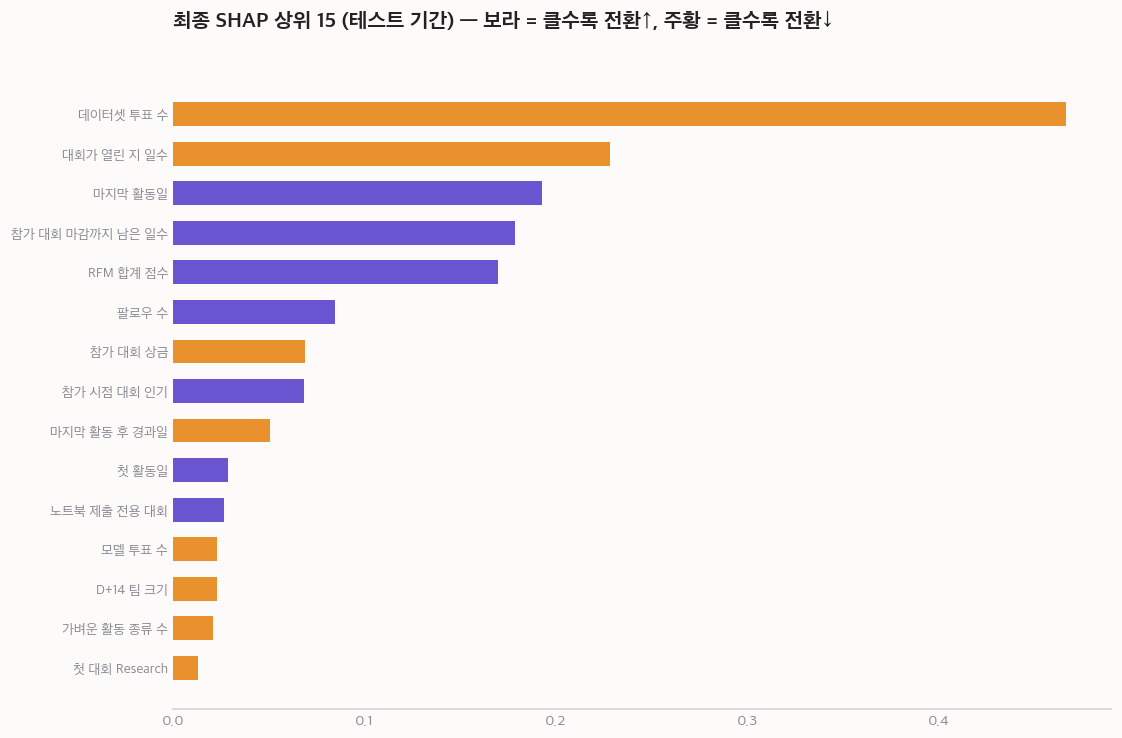

In [13]:
Xs = te_f[EXPLAIN_RUN["cols"]].sample(min(20000, len(te_f)), random_state=SEED)
final_imp, sv = shap_bar(EXPLAIN, Xs, "최종 SHAP 상위 15 (테스트 기간) — 보라 = 클수록 전환↑, 주황 = 클수록 전환↓", f"{FIG}/05_shap.png", top=15)
final_imp

["텍스트 겹침: '0.9' ↔ '상위 피처의 값에 따른 기여 — 결측'", "텍스트 겹침: '6000' ↔ '-0.3'"]


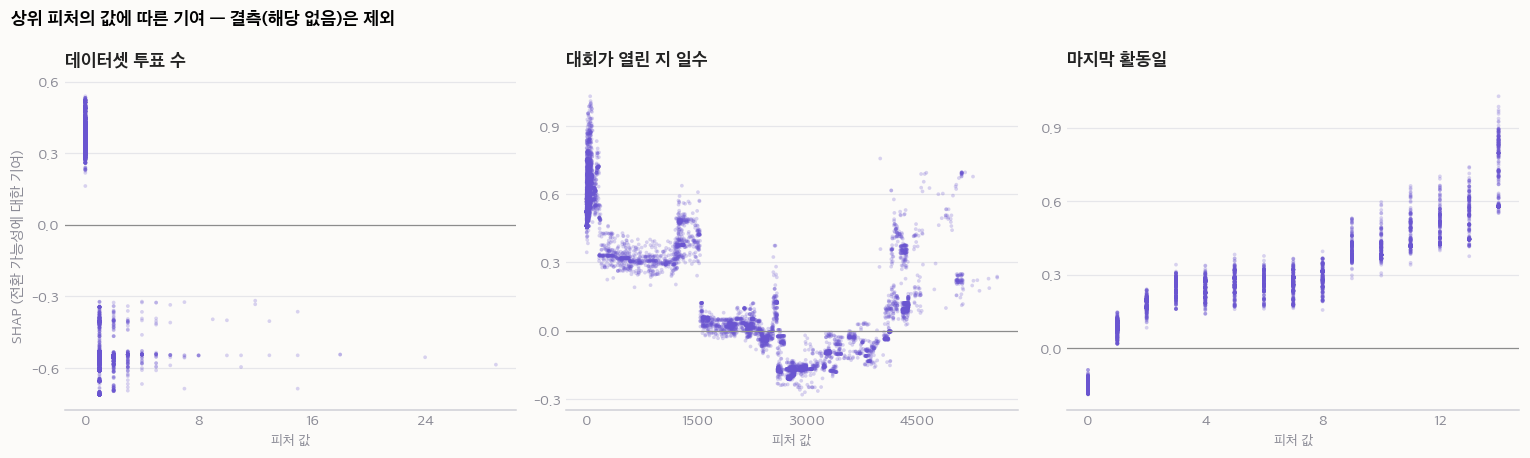

In [14]:
# 상위 3개 피처의 값에 따른 SHAP (의존도)
top3 = final_imp.index[:3]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
cols_idx = {c: i for i, c in enumerate(Xs.columns)}
for ax, c in zip(axes, top3):
    x = Xs[c].values; s = sv[:, cols_idx[c]]
    ok = ~np.isnan(x.astype(float))
    ax.scatter(x[ok], s[ok], s=6, alpha=0.25, color=vs.PURPLE, edgecolor="none")
    ax.axhline(0, color=vs.GRAY, lw=0.8)
    vs.panel_title(ax, LABEL.get(c, c)); ax.set_xlabel("피처 값", fontsize=9)
    ax.xaxis.set_major_locator(plt.MaxNLocator(5)); ax.yaxis.set_major_locator(plt.MaxNLocator(5))
    if c in ("max_comp_teams_at_join_open", "max_reward"):
        ax.set_xscale("symlog")
axes[0].set_ylabel("SHAP (전환 가능성에 대한 기여)")
fig.suptitle("상위 피처의 값에 따른 기여 — 결측(해당 없음)은 제외", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(f"{FIG}/05_shap_dependence.png", dpi=120, bbox_inches="tight"); print(vs.check_overlaps(fig))

## 결론

1. **쓸 수 있는 수준이다.** 신규 유저 상위 10%만 골라도 90일 안에 핵심 창작을 할 사람의 43%를 잡는다(무작위 대비 4.3배). 노트북 작성자 규칙과 합치면 상위 10%로 58%를 잡는다.
2. **성능을 올린 것은 알고리즘이 아니라 문제 이해였다.** 튜닝(+0.002), XGBoost, 앙상블은 fold 간 일관된 이득이 없었다. 반면 중간 SHAP에서 "마감까지 남은 일수"가 1위인 이유를 파고들어 **끝난 대회 참가 = 데이터 다운로드**라는 해석을 얻었고, 이를 피처로 만들자 모든 fold에서 올랐다.
3. **전환 신호 (A/B 테스트로 확인할 가설 후보)**
   - 데이터셋 투표만 하는 유저 → 전환 가능성 낮음: 데이터를 가져가러 온 유저. `04`의 "가벼운 활동 막다른 길"과 같은 집단
   - 막 열린 대회·마감까지 시간이 남은 대회에 참가 → 높음: 신규 유저를 **진행 중인 신규 대회**로 안내하는 실험
   - D+14에 가까울수록 활동 → 높음: 2주 차까지 다시 오게 하는 리마인드 실험
4. **성능의 한계는 데이터에 있다.** 대상의 95%가 14일 동안 하루만 활동한다. 알고리즘을 바꾸거나 2020년 데이터를 더해도(평균 +0.002, fold 3에서는 하락) 일관된 향상이 없다.

**RFM 참고**: 채택 규칙상 E10(RFM 추가)이 채택됐지만 향상 폭은 평균 0.0006으로 노이즈 수준이고, ablation에서도 RFM을 빼면 −0.0006이다. 14일 안 활동이 대부분 하루·한 건이라 F·M 구간이 나뉘지 않기 때문이다. 다음 실험부터는 채택 규칙에 최소 향상 폭(예: 0.002)을 더한다.

**한계**: 테스트 기간 3개월(5.6만 명) 한 번의 평가다. 조회·다운로드 기록이 없어 "둘러보는 행동"은 피처에 없다. SHAP은 모델 예측의 설명이지 인과 효과가 아니다.